[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/doomcodingbryan/STSCI4981/blob/main/notebooks/nfl_combine_speed.ipynb)

# Does Combine speed predict NFL value?

Bryan Chae (byc27) and Matthew Manno (mjm752), STSCI 4981/4982 capstone.
Draft classes 2016 to 2024.

**Part 1, sections 1 to 3**, describes the sample: who is in it, how complete the 40-yard dash data is, and
what the raw relationship between speed and playing time looks like.

**Part 2, sections 4 to 9**, tests whether that relationship survives once we account for where a player was
drafted.

This notebook only **reads** `data/combine_draft_outcomes_2016_2024.csv`. All cleaning lives in
`scripts/build_dataset.py`. See `CLAUDE.md` for the decisions behind every column used here.

Outcome: `y2_snap_share`, the share of possible team snaps a player was on the field for in their first two
NFL seasons, with missed games counted as 0.

Speed: `forty_z_pos`, the 40 time standardised within position group. It is a z-score, so a coefficient is
"change in snap share per one standard deviation of 40 time". **Negative means faster.**

Specialists (`pos_group == "ST"`: K, P, LS) are excluded throughout, because their snap share is about 0.


In [1]:
# Colab bootstrap. On Colab this downloads the project so the data file is there.
# On your own machine it does nothing, so the notebook runs the same either way.
import os
import subprocess
import sys

if "google.colab" in sys.modules:
    REPO_DIR = "/content/STSCI4981"
    if not os.path.isdir(REPO_DIR):
        subprocess.run(
            ["git", "clone", "--depth", "1", "-q",
             "https://github.com/doomcodingbryan/STSCI4981.git", REPO_DIR],
            check=True)
    os.chdir(f"{REPO_DIR}/notebooks")
    print("Running in Colab, working from", os.getcwd())


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)

df = pd.read_csv(ROOT / "data" / "combine_draft_outcomes_2016_2024.csv")
df = df[df["pos_group"] != "ST"].copy()

POS_ORDER = ["QB", "RB", "WR", "TE", "OL", "DL", "LB", "DB"]
df["pos_group"] = pd.Categorical(df["pos_group"], categories=POS_ORDER, ordered=True)

# Log of overall pick number. Pick 1 to pick 32 is a far bigger talent gap than pick 200 to pick 231,
# so the log scale matches how draft value actually falls off.
df["log_pick"] = np.log(df["draft_ovr"])

# Size-adjusted speed, standardised within position so it is on the same scale as forty_z_pos.
df["speed_score_z"] = df.groupby("pos_group", observed=True)["speed_score"].transform(
    lambda s: (s - s.mean()) / s.std())

# Complete cases on the two variables every model needs.
model_df = df.dropna(subset=["forty_z_pos", "y2_snap_share"]).copy()
drafted = model_df[model_df["drafted"]].copy()

print(f"all participants with a 40 time: {len(model_df)}")
print(f"of those, drafted:              {len(drafted)}")

# Rows used by the descriptive figures in part 1.
plot_df = df.dropna(subset=["forty", "y2_snap_share"])

df[["draft_class", "player_name", "pos_group", "forty", "y2_snap_share", "drafted"]].head()


all participants with a 40 time: 2429
of those, drafted:              1620


,draft_class,player_name,pos_group,forty,y2_snap_share,drafted
0,2016,Jared Goff,QB,4.82,0.657500,True
1,2016,Carson Wentz,QB,4.77,0.880313,True
2,2016,Joey Bosa,DL,4.86,0.674063,True
3,2016,Ezekiel Elliott,RB,4.47,0.603125,True
4,2016,Jalen Ramsey,DB,4.41,0.963437,True


[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/doomcodingbryan/STSCI4981/blob/main/notebooks/01_eda.ipynb)

# 01: Exploratory data analysis

Starter EDA for "Does Combine speed predict NFL on-field value?" (draft classes 2016 to 2024).

This notebook only **reads** `data/combine_draft_outcomes_2016_2024.csv`.
All cleaning lives in `scripts/build_dataset.py`; see `CLAUDE.md` for the decisions behind the columns used here.

Specialists (`pos_group == "ST"`: K, P, LS) are excluded everywhere, because their snap share is about 0.

## 1. Counts by class and position group

In [3]:
# Rows per class, with how many were drafted and how many have a 40 time.
by_class = df.groupby("draft_class").agg(
    players=("player_name", "size"),
    drafted=("drafted", "sum"),
    has_forty=("forty", "count"),
)
by_class["pct_drafted"] = (100 * by_class.drafted / by_class.players).round(1)
by_class["pct_with_forty"] = (100 * by_class.has_forty / by_class.players).round(1)
by_class

,players,drafted,has_forty,pct_drafted,pct_with_forty
draft_class,,,,,
2016,319,210,318,65.8,99.7
2017,316,220,265,69.6,83.9
2018,324,214,266,66.0,82.1
2019,329,215,257,65.3,78.1
2020,325,226,260,69.5,80.0
2021,440,220,391,50.0,88.9
2022,315,219,231,69.5,73.3
2023,307,219,221,71.3,72.0
2024,315,235,220,74.6,69.8


In [4]:
# Same two coverage numbers by position group.
by_pos = df.groupby("pos_group", observed=True).agg(
    players=("player_name", "size"),
    drafted=("drafted", "sum"),
    has_forty=("forty", "count"),
)
by_pos["pct_with_forty"] = (100 * by_pos.has_forty / by_pos.players).round(1)
by_pos

,players,drafted,has_forty,pct_with_forty
pos_group,,,,
QB,148,98,108,73.0
RB,286,168,240,83.9
WR,438,262,376,85.8
TE,179,116,136,76.0
OL,509,347,405,79.6
DL,519,378,422,81.3
LB,313,195,244,78.0
DB,598,414,498,83.3


In [5]:
# Class by position counts, to show the panel is roughly balanced across years.
pd.crosstab(df.draft_class, df.pos_group, margins=True)

pos_group,QB,RB,WR,TE,OL,DL,LB,DB,All
draft_class,,,,,,,,,
2016,18,29,43,15,53,63,39,59,319
2017,15,33,56,20,47,50,36,59,316
2018,19,32,44,17,48,63,31,70,324
2019,17,28,48,21,57,57,36,65,329
2020,17,30,55,20,52,46,44,61,325
2021,18,42,63,29,73,70,48,97,440
2022,15,36,40,21,58,52,32,61,315
2023,15,27,50,20,51,63,22,59,307
2024,14,29,39,16,70,55,25,67,315


## 2. The 40-yard dash by position group

The 40 is only comparable within a position group, so every figure splits on `pos_group`.

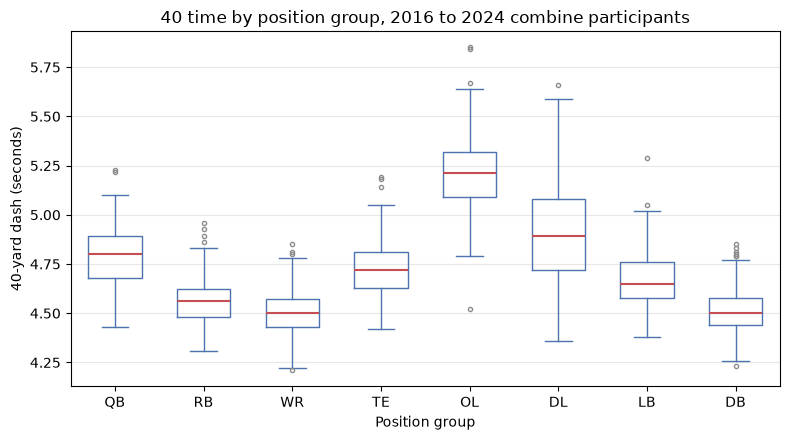

,count,mean,std,min,50%,max
pos_group,,,,,,
QB,108.0,4.79,0.15,4.43,4.80,5.23
RB,240.0,4.56,0.11,4.31,4.56,4.96
WR,376.0,4.51,0.10,4.21,4.50,4.85
TE,136.0,4.73,0.14,4.42,4.72,5.19
OL,405.0,5.21,0.18,4.52,5.21,5.85
DL,422.0,4.91,0.24,4.36,4.89,5.66
LB,244.0,4.67,0.14,4.38,4.65,5.29
DB,498.0,4.51,0.10,4.23,4.50,4.85


In [6]:
forty_by_pos = [df.loc[df.pos_group == p, "forty"].dropna() for p in POS_ORDER]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.boxplot(forty_by_pos, tick_labels=POS_ORDER, widths=0.6,
           medianprops=dict(color="#C44E52", linewidth=1.5),
           boxprops=dict(color="#4C72B0"),
           whiskerprops=dict(color="#4C72B0"),
           capprops=dict(color="#4C72B0"),
           flierprops=dict(marker="o", markersize=3, markerfacecolor="none",
                           markeredgecolor="#8C8C8C"))
ax.set_xlabel("Position group")
ax.set_ylabel("40-yard dash (seconds)")
ax.set_title("40 time by position group, 2016 to 2024 combine participants")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(FIGURES / "eda_forty_by_pos_group.png", dpi=300)
plt.show()

df.groupby("pos_group", observed=True)["forty"].describe()[["count", "mean", "std", "min", "50%", "max"]].round(2)

## 3. Playing time against 40 time

`y2_snap_share` is the primary outcome: snaps in the player's first two NFL seasons as a share of all team games
(missed games count as 0). Players who never played are coded 0, so the mass at 0 is real, not missing data.

These are unadjusted scatters. Draft position is a likely confounder and is handled in part 2 below.

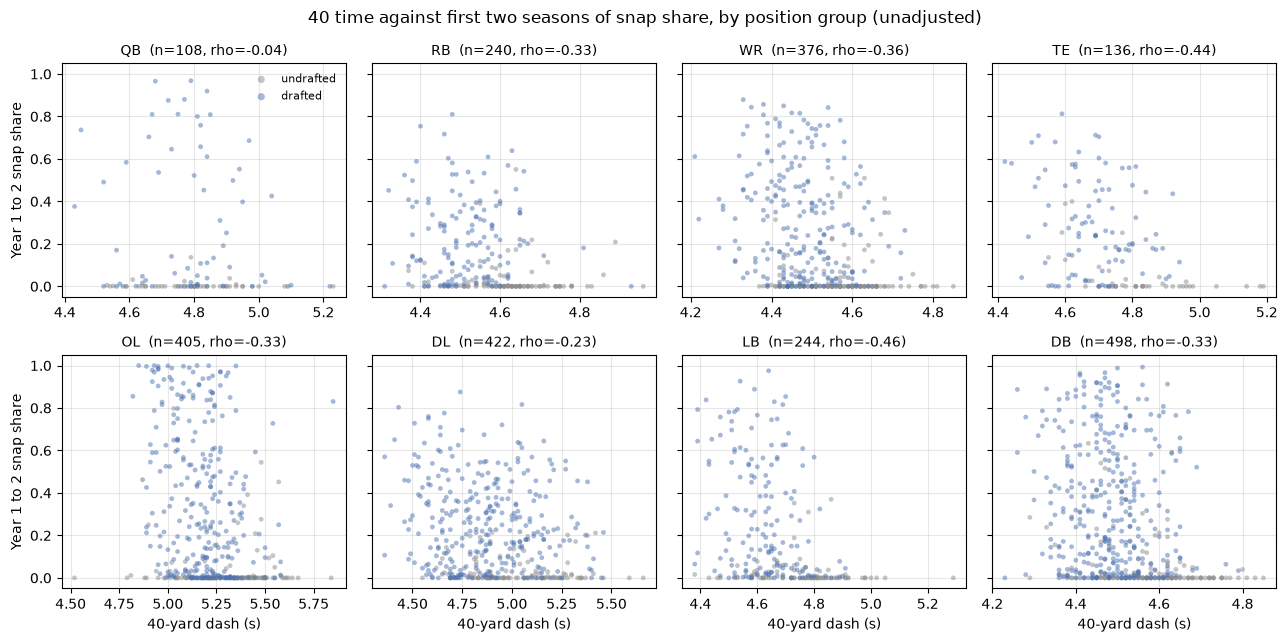

In [7]:
plot_df = df.dropna(subset=["forty", "y2_snap_share"])

fig, axes = plt.subplots(2, 4, figsize=(13, 6.5), sharey=True)
for ax, pos in zip(axes.flat, POS_ORDER):
    g = plot_df[plot_df.pos_group == pos]
    # Color by draft status, since undrafted players sit almost entirely at 0.
    # Loop variable is is_drafted, not drafted: `drafted` is the model sample defined above.
    for is_drafted, color, label in [(False, "#8C8C8C", "undrafted"), (True, "#4C72B0", "drafted")]:
        s = g[g.drafted == is_drafted]
        ax.scatter(s.forty, s.y2_snap_share, s=12, alpha=0.5, c=color,
                   edgecolors="none", label=label)
    rho = g[["forty", "y2_snap_share"]].corr(method="spearman").iloc[0, 1]
    ax.set_title(f"{pos}  (n={len(g)}, rho={rho:.2f})", fontsize=10)
    ax.grid(alpha=0.3)
    ax.set_axisbelow(True)

for ax in axes[-1]:
    ax.set_xlabel("40-yard dash (s)")
for ax in axes[:, 0]:
    ax.set_ylabel("Year 1 to 2 snap share")
axes.flat[0].legend(fontsize=8, markerscale=1.5, frameon=False)
fig.suptitle("40 time against first two seasons of snap share, by position group (unadjusted)")
fig.tight_layout()
fig.savefig(FIGURES / "eda_forty_vs_y2_snap_share.png", dpi=300)
plt.show()

In [8]:
# Within-position Spearman correlations, the table version of the figure above.
(plot_df.groupby("pos_group", observed=True)
        .apply(lambda g: g.forty.corr(g.y2_snap_share, method="spearman"), include_groups=False)
        .round(2)
        .sort_values()
        .rename("spearman_forty_vs_y2_snap_share")
        .to_frame())

,spearman_forty_vs_y2_snap_share
pos_group,
LB,-0.46
TE,-0.44
WR,-0.36
RB,-0.33
OL,-0.33
DB,-0.33
DL,-0.23
QB,-0.04


## Part 2: does any of that survive the draft?

Everything above is descriptive. Faster players play more, but faster players are also drafted earlier, and
earlier picks play more regardless of how fast they are. The rest of this notebook asks whether 40 time still
predicts playing time **after** accounting for where a player was taken.


## 4. The main result

Three models, each with position-group fixed effects so players are only ever compared within their own
position. Standard errors are heteroskedasticity robust (HC3), because snap share is bounded at 0 and 1 and
its variance is far from constant.

1. **All participants.** The raw association, drafted and undrafted together.
2. **Drafted only.** Same model on drafted players, so the sample matches model 3.
3. **Drafted only, controlling for draft position.** The test that matters.

The number to watch is how much the speed coefficient shrinks between models 2 and 3.

In [9]:
m1 = smf.ols("y2_snap_share ~ forty_z_pos + C(pos_group)", data=model_df).fit(cov_type="HC3")
m2 = smf.ols("y2_snap_share ~ forty_z_pos + C(pos_group)", data=drafted).fit(cov_type="HC3")
m3 = smf.ols("y2_snap_share ~ forty_z_pos + log_pick + C(pos_group)", data=drafted).fit(cov_type="HC3")

def row(name, fit, n):
    return {
        "model": name,
        "n": n,
        "beta_speed": round(fit.params["forty_z_pos"], 4),
        "se": round(fit.bse["forty_z_pos"], 4),
        "p": round(fit.pvalues["forty_z_pos"], 4),
        "r2": round(fit.rsquared, 3),
    }

main = pd.DataFrame([
    row("1. all participants", m1, len(model_df)),
    row("2. drafted only", m2, len(drafted)),
    row("3. drafted, + log(pick)", m3, len(drafted)),
]).set_index("model")
main

,n,beta_speed,se,p,r2
model,,,,,
1. all participants,2429,-0.0759,0.0048,0.0000,0.106
2. drafted only,1620,-0.0517,0.0074,0.0000,0.058
"3. drafted, + log(pick)",1620,-0.0006,0.0063,0.9266,0.401


In [10]:
shrink = 100 * (1 - m3.params["forty_z_pos"] / m2.params["forty_z_pos"])
print(f"speed coefficient among drafted players:        {m2.params['forty_z_pos']:+.4f}")
print(f"after controlling for log(overall pick):        {m3.params['forty_z_pos']:+.4f}")
print(f"shrinkage:                                      {shrink:.0f}%")
print(f"coefficient on log(pick):                       {m3.params['log_pick']:+.4f} "
      f"(p = {m3.pvalues['log_pick']:.1e})")

speed coefficient among drafted players:        -0.0517
after controlling for log(overall pick):        -0.0006
shrinkage:                                      99%
coefficient on log(pick):                       -0.1805 (p = 1.6e-183)


## 5. The same test one position at a time

Pooled fixed effects assume speed matters equally everywhere. It almost certainly does not, so we refit
within each position group, drafted players only, before and after the draft control.

Read `pct_shrink` with care: where the coefficient changes sign (RB, WR, DB) the percentage is not meaningful, and the point is simply that no speed effect survives the draft control.


In [11]:
rows = []
for pos in POS_ORDER:
    g = drafted[drafted["pos_group"] == pos]
    before = smf.ols("y2_snap_share ~ forty_z_pos", data=g).fit(cov_type="HC3")
    after = smf.ols("y2_snap_share ~ forty_z_pos + log_pick", data=g).fit(cov_type="HC3")
    rows.append({
        "pos": pos,
        "n": len(g),
        "beta_before": before.params["forty_z_pos"],
        "p_before": before.pvalues["forty_z_pos"],
        "beta_after": after.params["forty_z_pos"],
        "p_after": after.pvalues["forty_z_pos"],
    })

by_pos = pd.DataFrame(rows).set_index("pos")
by_pos["pct_shrink"] = (100 * (1 - by_pos.beta_after / by_pos.beta_before)).round(0)
by_pos.round(4)

,n,beta_before,p_before,beta_after,p_after,pct_shrink
pos,,,,,,
QB,65,-0.0395,0.2510,-0.0040,0.8726,90.0
RB,142,-0.0040,0.8431,0.0199,0.2395,596.0
WR,227,-0.0501,0.0021,0.0218,0.1878,143.0
TE,92,-0.0578,0.0357,-0.0077,0.7568,87.0
OL,282,-0.1031,0.0001,-0.0190,0.4102,82.0
DL,309,-0.0301,0.0129,-0.0015,0.8713,95.0
LB,153,-0.0988,0.0001,-0.0054,0.7774,95.0
DB,350,-0.0384,0.0403,0.0101,0.5455,126.0


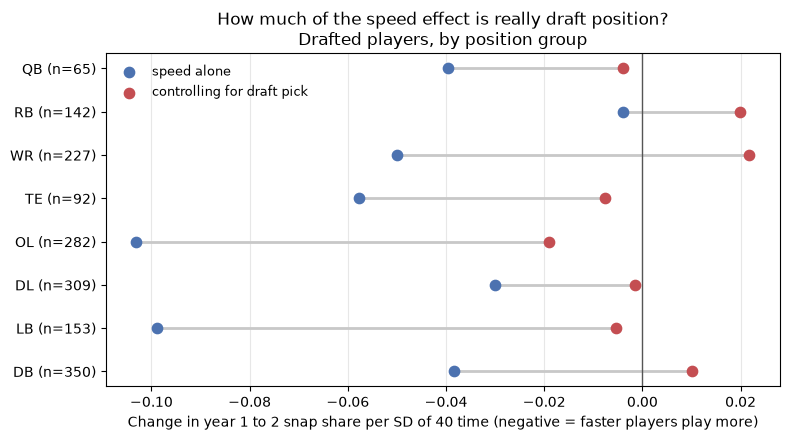

In [12]:
fig, ax = plt.subplots(figsize=(8, 4.5))
y = np.arange(len(by_pos))[::-1]

# Dumbbell: the line is how much of the raw speed effect draft position absorbs.
ax.hlines(y, by_pos.beta_before, by_pos.beta_after, color="#C8C8C8", linewidth=2, zorder=1)
ax.scatter(by_pos.beta_before, y, s=55, color="#4C72B0", zorder=2, label="speed alone")
ax.scatter(by_pos.beta_after, y, s=55, color="#C44E52", zorder=2, label="controlling for draft pick")
ax.axvline(0, color="#555555", linewidth=1)

ax.set_yticks(y, [f"{p} (n={n})" for p, n in zip(by_pos.index, by_pos.n)])
ax.set_xlabel("Change in year 1 to 2 snap share per SD of 40 time (negative = faster players play more)")
ax.set_title("How much of the speed effect is really draft position?\nDrafted players, by position group")
ax.legend(frameon=False, fontsize=9)
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(FIGURES / "model_speed_coef_by_pos.png", dpi=300)
plt.show()

## 6. Which speed measure works best?

`forty_z_pos` is raw speed within position. `speed_score` is weight adjusted (wt x 200 / forty^4), which is
the measure scouts use to say a big player is fast *for their size*. Both are standardised within position,
so the coefficients are directly comparable.

In [13]:
measures = {}
for name, var in [("forty_z_pos", "forty_z_pos"), ("speed_score_z", "speed_score_z")]:
    g = drafted.dropna(subset=[var])
    a = smf.ols(f"y2_snap_share ~ {var} + C(pos_group)", data=g).fit(cov_type="HC3")
    b = smf.ols(f"y2_snap_share ~ {var} + log_pick + C(pos_group)", data=g).fit(cov_type="HC3")
    measures[name] = {
        "n": len(g),
        "beta_alone": round(a.params[var], 4),
        "p_alone": round(a.pvalues[var], 4),
        "beta_with_pick": round(b.params[var], 4),
        "p_with_pick": round(b.pvalues[var], 4),
        "r2_with_pick": round(b.rsquared, 3),
    }

pd.DataFrame(measures).T

,n,beta_alone,p_alone,beta_with_pick,p_with_pick,r2_with_pick
forty_z_pos,1620.0,-0.0517,0.0,-0.0006,0.9266,0.401
speed_score_z,1612.0,0.0616,0.0,0.0028,0.6585,0.401


## 7. Who skipped the 40, and does it bias us?

Caveat 1 in `CLAUDE.md`: missing drills are not random. Top prospects have the least to gain from running,
so if the players who skipped the 40 are better than the ones who ran it, dropping them understates how well
the best players do and biases the whole analysis.

In [14]:
drafted_all = df[df["drafted"]].copy()
drafted_all["ran_forty"] = drafted_all["forty_z_pos"].notna()

skip = drafted_all.groupby("ran_forty").agg(
    n=("player_name", "size"),
    mean_pick=("draft_ovr", "mean"),
    mean_y2_snap_share=("y2_snap_share", "mean"),
    pct_made_nfl=("made_nfl", "mean"),
).round(3)
skip.index = ["skipped the 40", "ran the 40"]

print(skip.to_string())
print()
# Round 1 is where skipping is most common, so check it on its own.
r1 = drafted_all[drafted_all["draft_round"] == 1]
print("round 1 only:")
print(r1.groupby("ran_forty")["y2_snap_share"].agg(["size", "mean"]).round(3).to_string())

                   n  mean_pick  mean_y2_snap_share  pct_made_nfl
skipped the 40   358    113.891               0.320         0.941
ran the 40      1620    118.572               0.314         0.957

round 1 only:
           size   mean
ran_forty             
False        57  0.629
True        223  0.613


## 8. Sensitivity check: drop the 2021 class

Caveat 2: the 2021 Combine was cancelled, so 2021 numbers are pro day times from a larger and more
self-selected pool. Pro day times run fast. If the main result depends on 2021, it is not a real result.

In [15]:
no_2021 = drafted[~drafted["pro_day_2021"]]
m3_no21 = smf.ols("y2_snap_share ~ forty_z_pos + log_pick + C(pos_group)",
                  data=no_2021).fit(cov_type="HC3")

pd.DataFrame([
    row("full sample", m3, len(drafted)),
    row("without 2021", m3_no21, len(no_2021)),
]).set_index("model")

,n,beta_speed,se,p,r2
model,,,,,
full sample,1620,-0.0006,0.0063,0.9266,0.401
without 2021,1427,0.0002,0.0069,0.9807,0.396


## 8b. Sensitivity check: drop the 2016 class

**This one is Matthew's.**

Caveat 3 in `CLAUDE.md`: 99.7% of the 2016 class has a 40 time, against about 80% from 2017 on. That is a
suspiciously large gap, and it suggests the source recorded 2016 differently. If the main result only holds
because of 2016, we need to know before we write it up.

The cell below is the same model as section 8, with one line left blank. Section 8 kept everyone except the
2021 pro day class by writing `drafted[~drafted["pro_day_2021"]]`. Do the same thing for 2016, using the
`draft_class` column instead. Then run the cell and compare the speed coefficient against the full sample.


In [16]:
# TODO (Matthew): replace None below with the filter that drops the 2016 draft class.
# Section 8 did it for 2021 like this:   drafted[~drafted["pro_day_2021"]]
# You want the rows where draft_class is not 2016.
no_2016 = None

m3_no16 = None
if no_2016 is None:
    print("Not run yet. Fill in the line above, then run this cell again.")
else:
    m3_no16 = smf.ols("y2_snap_share ~ forty_z_pos + log_pick + C(pos_group)",
                      data=no_2016).fit(cov_type="HC3")
    print(pd.DataFrame([
        row("full sample", m3, len(drafted)),
        row("without 2016", m3_no16, len(no_2016)),
    ]).set_index("model").to_string())


Not run yet. Fill in the line above, then run this cell again.


## 9. Results file for the write-up

Everything above, written to `reports/results_update2.md` so the update and the paper can quote numbers
without rerunning anything.

In [17]:
out = ROOT / "reports" / "results_update2.md"
with out.open("w") as f:
    f.write("# Update 2 model results\n\n")
    f.write("Generated by `notebooks/02_models.ipynb`. Do not edit by hand; rerun the notebook.\n\n")
    f.write("Outcome: y2_snap_share. Speed: forty_z_pos (within-position z-score, negative = faster).\n")
    f.write("All models include position-group fixed effects and HC3 robust standard errors.\n\n")
    f.write("## Main models\n\n" + main.to_markdown() + "\n\n")
    f.write(f"Speed coefficient shrinks {shrink:.0f}% once log(overall pick) is added.\n\n")
    f.write("## By position group (drafted only)\n\n" + by_pos.round(4).to_markdown() + "\n\n")
    f.write("## Speed measures compared\n\n" + pd.DataFrame(measures).T.to_markdown() + "\n\n")
    f.write("## Drafted players who skipped the 40\n\n" + skip.to_markdown() + "\n\n")
    f.write("## Sensitivity: 2021 pro day class removed\n\n")
    f.write(f"Speed coefficient {m3.params['forty_z_pos']:+.4f} (full) vs "
            f"{m3_no21.params['forty_z_pos']:+.4f} (without 2021), "
            f"n = {len(drafted)} vs {len(no_2021)}.\n")
    if m3_no16 is not None:
        f.write("\n## Sensitivity: 2016 class removed\n\n")
        f.write(f"Speed coefficient {m3.params['forty_z_pos']:+.4f} (full) vs "
                f"{m3_no16.params['forty_z_pos']:+.4f} (without 2016), "
                f"n = {len(drafted)} vs {len(no_2016)}.\n")

print(out.read_text())

# Update 2 model results

Generated by `notebooks/02_models.ipynb`. Do not edit by hand; rerun the notebook.

Outcome: y2_snap_share. Speed: forty_z_pos (within-position z-score, negative = faster).
All models include position-group fixed effects and HC3 robust standard errors.

## Main models

| model                   |    n |   beta_speed |     se |      p |    r2 |
|:------------------------|-----:|-------------:|-------:|-------:|------:|
| 1. all participants     | 2429 |      -0.0759 | 0.0048 | 0      | 0.106 |
| 2. drafted only         | 1620 |      -0.0517 | 0.0074 | 0      | 0.058 |
| 3. drafted, + log(pick) | 1620 |      -0.0006 | 0.0063 | 0.9266 | 0.401 |

Speed coefficient shrinks 99% once log(overall pick) is added.

## By position group (drafted only)

| pos   |   n |   beta_before |   p_before |   beta_after |   p_after |   pct_shrink |
|:------|----:|--------------:|-----------:|-------------:|----------:|-------------:|
| QB    |  65 |       -0.0395 |     0.251  |    

## Notes and limitations to carry into the paper

- `y2_snap_share` is bounded between 0 and 1 with a large spike at exactly 0 (players who never played).
  OLS ignores both facts. A fractional logit or a two-part model is the right robustness check, and belongs
  in Update 3, not here.
- Draft position is a **post-treatment** control in one reading: teams partly draft players because they ran
  fast, so controlling for pick number removes some of speed's real effect. The honest claim is a bound.
  Model 2 is the upper bound on how much speed matters, model 3 is the lower bound.
- Complete-case only. Section 7 shows who that leaves out.
- Still open: the AV secondary outcome, the 2016 and `pfr_id_source` sensitivity checks, and the shuttle.